# The adaptive loop in the WISP simulator

**Question.** Can the server start from full frames, learn a compact code for *this* room without any labels, hand that code to the tag, and keep it working as the room changes? This is approach category 5, and the first experiment where the tag's behaviour is set by instructions from the server.

**How the loop works** (`semwisp/server/adaptive.py`, `semwisp/tag/interval.py`).
1. *Bootstrap.* Every query fetches the full 160×120 frame (19,200 bytes). A pretrained COCO person detector (the *teacher*) scores it. Frames it is confident about (score ≥ 0.6 person, ≤ 0.3 empty) become training examples.
2. *Learn.* After 200 such frames the server fits an **interval code**: for each of 252 candidate cells (the blocks of the 4×3, 8×6 and 16×12 grids) it finds the gray-level range the cell stays in when the room is empty, then picks the *K* cells whose "outside its range" bit best predicts the teacher's labels. The decoder is a logistic regression on those *K* bits.
3. *Configure.* The server sends the tag the *K* cells and their ranges (3 bytes per cell). From then on the tag answers with *K* bits: one compare-against-range per cell, no division.
4. *Check and adapt.* Every so often the server also asks for the full frame and compares the teacher's answer with the code's. The more they disagree, the more often it checks (between every 2nd and every 64th query). After 50 new labelled frames it refits the code and reconfigures the tag.

**Stream.** The five annotated PIROPO sequences in recording order (`training`, `test3`, `test1`, `training_seats`, `test2`), every 2nd frame, treated as one deployment of about 30 minutes and 3,400 queries. Ground truth is used only for scoring. The stream is then replayed a second time without resetting anything: pass 1 is the honest test, pass 2 is optimistic (the same frames again) and shows what happens once the server has seen what this room does.

**Metric.** Balanced accuracy of the server's yes/no answer (mean of the person and empty recall) over the queries after the bootstrap, and uplink bytes per query including the full frames fetched for checking.

**Findings in brief.**
1. **The loop works as a mechanism.** With no labels, the tag ends up answering most queries with 12 bytes, and adapting beats learning once by a wide margin: balanced accuracy 0.83 against 0.66 on the first pass.
2. **On the first pass it is not cheap.** The server still fetches a full frame on 25% of queries, so the average uplink is about 4,800 bytes per query: a 4× saving over sending every frame, not a 1,000× one. The cost of the loop is the checking, not the code.
3. **The reason is novelty, not the loop.** PIROPO is a staged recording in which every few minutes is a new scenario. Shown the same 30 minutes a second time, the server fetches a full frame on 2.6% of queries (513 bytes per query, 37× less than sending every frame) and its accuracy (0.88) matches the detector looking at every full frame (0.86).
4. **The teacher is now the ceiling.** With true labels in place of the detector the second pass reaches 0.95. The detector at 160×120 is only 0.86 accurate itself, and its mistakes both mislabel training frames and trigger needless checks.
5. **Smaller codes cost more in total.** With 32 or 8 bits the code disagrees with the teacher more often, the server checks more, and the total bytes per query go up, not down.

This data can show that the mechanism works and where it breaks. It cannot show how the loop behaves over days in a real room, which is the result that matters; that needs the data you are about to collect.


## 1. Results per configuration

In [5]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

sys.path.insert(0, str(Path('..').resolve()))
from semwisp import piropo
from semwisp.frames import load_frames
from semwisp.tag.interval import CELLS, IntervalCode, cell_sums, code_bits

INK, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'text.color': INK, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.titlesize': 10, 'axes.titlelocation': 'left'})

R, rows = {}, []
for f in sorted((piropo.REPO / 'results' / 'adaptive_loop').glob('*.npz')):
    with np.load(f) as z:
        m = json.loads(str(z['meta']))
        R[m['name']] = dict(df=pd.DataFrame({c: z[c] for c in z.files if c != 'meta' and not c.startswith('code_')}),
                            code=IntervalCode(z['code_cell'], z['code_lo'], z['code_hi']), weight=z['code_weight'], meta=m)
        for p, s in m['by_pass'].items():
            rows.append(dict(config=m['name'], labels='ground truth' if m['kind'].startswith('oracle') else 'detector',
                             bits=m['k'], **{'pass': int(p)}, balanced_acc=s['balanced_accuracy'],
                             auc_code_only=s['auc_code_only'], up_bytes_per_query=s['up_bytes_per_query'],
                             full_frame_fraction=s['explored_fraction'], reconfigs=s['reconfigs'],
                             down_bytes=s['down_bytes_total']))
res = pd.DataFrame(rows).sort_values(['labels', 'config', 'pass']).reset_index(drop=True)

# reference: fetch the full frame on every query and let the teacher answer
d0 = R['adaptive_k96']['df']; d0 = d0[d0['pass'] == 1]
ans = (d0.teacher >= 0.45).astype(int)
teacher_bal = (ans[d0.label == 1].mean() + (1 - ans[d0.label == 0]).mean()) / 2
print(f'teacher on every full frame: balanced accuracy {teacher_bal:.3f} at 19,200 bytes per query')
res.style.format({'balanced_acc': '{:.3f}', 'auc_code_only': '{:.3f}', 'up_bytes_per_query': '{:,.0f}',
                  'full_frame_fraction': '{:.1%}', 'down_bytes': '{:,.0f}'}).hide(axis='index')

teacher on every full frame: balanced accuracy 0.864 at 19,200 bytes per query


config,labels,bits,pass,balanced_acc,auc_code_only,up_bytes_per_query,full_frame_fraction,reconfigs,down_bytes
adaptive_k32,detector,32,1,0.841,0.894,"5,513",28.7%,17,"1,632"
adaptive_k32,detector,32,2,0.856,0.940,"3,586",18.7%,11,"1,056"
adaptive_k8,detector,8,1,0.794,0.811,"8,171",42.6%,25,600
adaptive_k8,detector,8,2,0.767,0.695,"7,323",38.1%,24,576
adaptive_k96,detector,96,1,0.834,0.913,"4,788",24.9%,15,"4,320"
adaptive_k96,detector,96,2,0.884,0.919,513,2.6%,2,576
static_k96,detector,96,1,0.657,0.737,12,0.0%,1,288
static_k96,detector,96,2,0.676,0.761,12,0.0%,0,0
oracle_k96,ground truth,96,1,0.898,0.884,"4,721",24.5%,16,"4,608"
oracle_k96,ground truth,96,2,0.954,0.981,879,4.5%,3,864


**Reading the table.** `balanced_acc` and `up_bytes_per_query` cover the queries after the bootstrap (the first pass also spent about 210 queries on full frames before the first code existed; including those, pass 1 of `adaptive_k96` averages 5,700 bytes per query). `auc_code_only` is the AUC of the 12-byte answers alone, on the queries where no full frame was fetched. `down_bytes` is the total sent to the tag as configurations: 288 bytes each for 96 cells, which is negligible next to even one 19,200-byte frame.

* **Adaptive against learn-once** (`adaptive_k96` and `static_k96`): 0.834 against 0.657 in pass 1. A code fitted to the first three minutes does not survive the rest of the recording, with detector labels or with true ones (`oracle_static_k96`: 0.624).
* **Pass 1 against pass 2**: full-frame requests fall from 24.9% to 2.6% for 96 bits with detector labels, and from 24.5% to 4.5% with true labels.
* **Fewer bits**: 32 bits is close to 96 bits on accuracy in pass 1 but does not settle in pass 2 (18.7% full frames). 8 bits never settles (about 40% full frames in both passes) and is the most expensive configuration here.


## 2. Accuracy against bytes per query

Each point is one configuration in one pass. The teacher answering from a full frame on every query is the reference at the right.

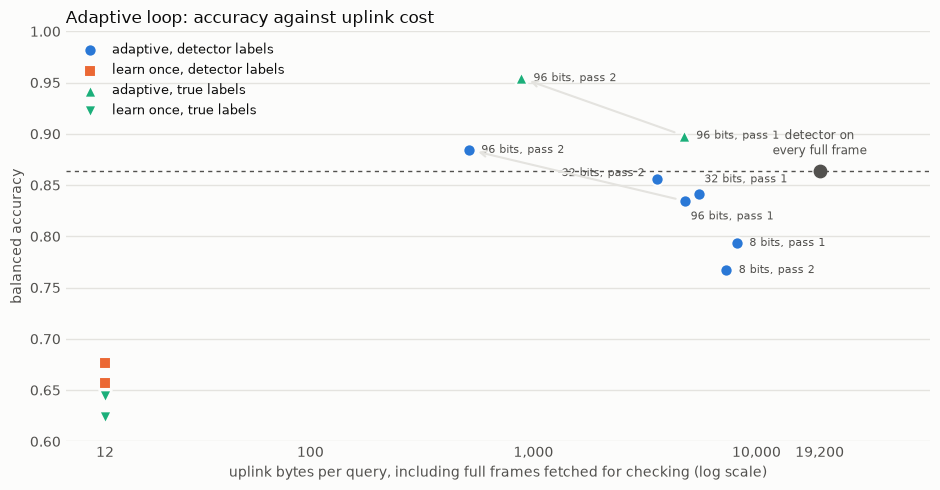

In [2]:
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.axhline(teacher_bal, color=MUTED, lw=1, ls=(0, (3, 3)))
ax.scatter([19200], [teacher_bal], s=80, color=MUTED, zorder=3)
ax.annotate('detector on\nevery full frame', (19200, teacher_bal), (0, 20), textcoords='offset points', ha='center',
            va='center', fontsize=8.5, color=MUTED)
OFF = {('adaptive_k32', 2): (-9, 4, 'right'), ('adaptive_k32', 1): (4, 11, 'left'), ('adaptive_k96', 1): (4, -11, 'left')}
LAB = {'adaptive': ('adaptive, detector labels', BLUE, 'o'), 'static': ('learn once, detector labels', ORANGE, 's'),
       'oracle': ('adaptive, true labels', AQUA, '^'), 'oracle_static': ('learn once, true labels', AQUA, 'v')}
for kind, (label, color, marker) in LAB.items():
    d = res[[R[c]['meta']['kind'] == kind for c in res.config]]
    ax.scatter(d.up_bytes_per_query, d.balanced_acc, s=80, color=color, marker=marker, edgecolor=SURFACE, linewidth=1.5,
               label=label, zorder=3)
    for r in d.itertuples():
        if 'static' in kind:                       # both passes sit together at 12 bytes; the legend names them
            continue
        dx, dy, ha = OFF.get((r.config, r._4), (9, 0, 'left'))
        ax.annotate(f"{r.bits} bits, pass {r._4}", (r.up_bytes_per_query, r.balanced_acc), (dx, dy),
                    textcoords='offset points', va='center', ha=ha, fontsize=8, color=MUTED)
for c in ['adaptive_k96', 'oracle_k96']:           # pass 1 -> pass 2
    d = res[res.config == c].sort_values('pass')
    ax.annotate('', (d.up_bytes_per_query.iloc[1], d.balanced_acc.iloc[1]), (d.up_bytes_per_query.iloc[0], d.balanced_acc.iloc[0]),
                arrowprops=dict(arrowstyle='->', color=GRID, lw=1.5, shrinkA=7, shrinkB=7))
ax.set_xscale('log'); ax.set_xlim(8, 60000); ax.set_ylim(0.6, 1.0)
ax.set_xticks([12, 100, 1000, 10000, 19200], ['12', '100', '1,000', '10,000', '19,200']); ax.minorticks_off()
ax.set_xlabel('uplink bytes per query, including full frames fetched for checking (log scale)')
ax.set_ylabel('balanced accuracy'); ax.set_title('Adaptive loop: accuracy against uplink cost', fontsize=12)
ax.grid(axis='y', color=GRID, lw=1); ax.set_axisbelow(True); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(frameon=False, loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

**Reading the chart.** Left is cheaper, up is better. The learn-once points sit at 12 bytes and 0.62–0.68: cheap and wrong. The adaptive points in pass 1 sit at 4,700–8,200 bytes, only a little left of the full-frame reference. The arrows show what the second pass changes for the 96-bit code: about a factor of ten to the left with detector labels, to a point level with the detector-on-every-frame line, and to 0.95 with true labels. The gap between the blue and green points at the top is what a better teacher would buy.


## 3. The loop over time

The 96-bit configuration with detector labels, both passes. Top: share of queries that fetched a full frame (rolling over 100 queries). Bottom: share of answers that match the ground truth (same window). Ticks along the top mark the queries where the tag was sent a new configuration.

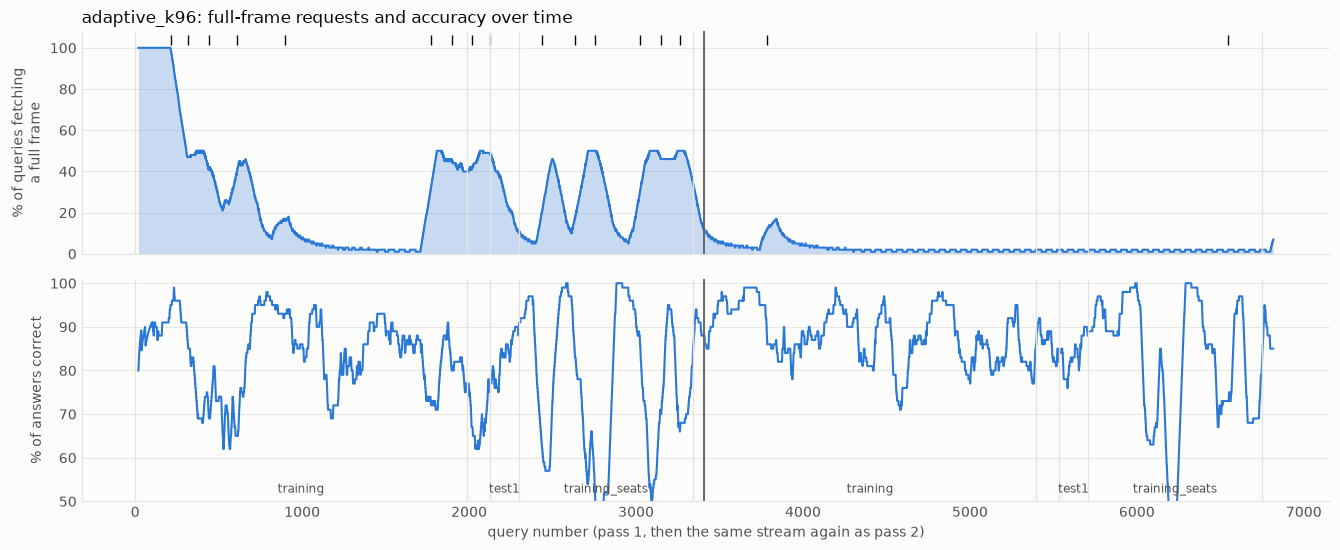

In [3]:
def timeline(name, win=100):
    d = R[name]['df'].reset_index(drop=True)
    x = np.arange(len(d))
    roll = lambda v: pd.Series(v.astype(float)).rolling(win, min_periods=20).mean()
    fig, axes = plt.subplots(2, 1, figsize=(13.5, 5.6), sharex=True, height_ratios=[1, 1])
    axes[0].fill_between(x, roll(d.explored.values) * 100, color=BLUE, alpha=0.25, lw=0)
    axes[0].plot(x, roll(d.explored.values) * 100, color=BLUE, lw=1.5)
    axes[0].plot(x[d.reconfig.values], np.full(d.reconfig.sum(), 104), '|', color=INK, ms=7)
    axes[0].set_ylabel('% of queries fetching\na full frame'); axes[0].set_ylim(0, 108)
    axes[1].plot(x, roll((d.answer == d.label).values) * 100, color=BLUE, lw=1.5)
    axes[1].set_ylabel('% of answers correct'); axes[1].set_ylim(50, 101)
    axes[1].set_xlabel('query number (pass 1, then the same stream again as pass 2)')
    starts = np.flatnonzero((d.seq != d.seq.shift()) | (d['pass'] != d['pass'].shift()))
    for ax in axes:
        for s in starts:
            ax.axvline(s, color=GRID, lw=1)
        ax.axvline(starts[len(starts) // 2], color=MUTED, lw=1.2)
        ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True); ax.tick_params(length=0)
        for sp in ('top', 'right'):
            ax.spines[sp].set_visible(False)
    for s, e in zip(starts, list(starts[1:]) + [len(d)]):
        if e - s > 150:
            axes[1].text((s + e) / 2, 52, d.seq[s], ha='center', fontsize=8.5, color=MUTED)
    axes[0].set_title(f"{name}: full-frame requests and accuracy over time", fontsize=12)
    plt.tight_layout(); plt.show()

timeline('adaptive_k96')

**What happens over time.**
* The bootstrap is the flat 100% at the start. After the first configuration the check rate falls in steps, reaching about 2% (every 64th query, the floor) by query 1,000.
* The check rate jumps back to 40–50% three times in pass 1: late in `training` (around query 1,800, continuing through `test3` and `test1`), and twice in `training_seats`, where the furniture has moved. Each jump is followed by reconfigurations (the ticks) and then recovery. That is the loop doing its job.
* In pass 2 the check rate stays near the floor. But the accuracy still dips to 50–65% in `training_seats` (around query 6,200) without the check rate reacting. At one check per 64 queries the server takes hundreds of queries to notice a problem, and it compares against the detector, not the truth. A check interval of 64 is too slow a floor for a room that changes this fast.
* In an extra run that replayed the stream four times (not saved in `results/`), the detector-labelled loop did not stay settled: full-frame requests were 2.6% in pass 2, then 19% and 13% in passes 3 and 4. With a noisy teacher the settled state is fragile.


The same view with ground-truth labels in place of the detector, to separate what the loop does from what the teacher's mistakes do to it:

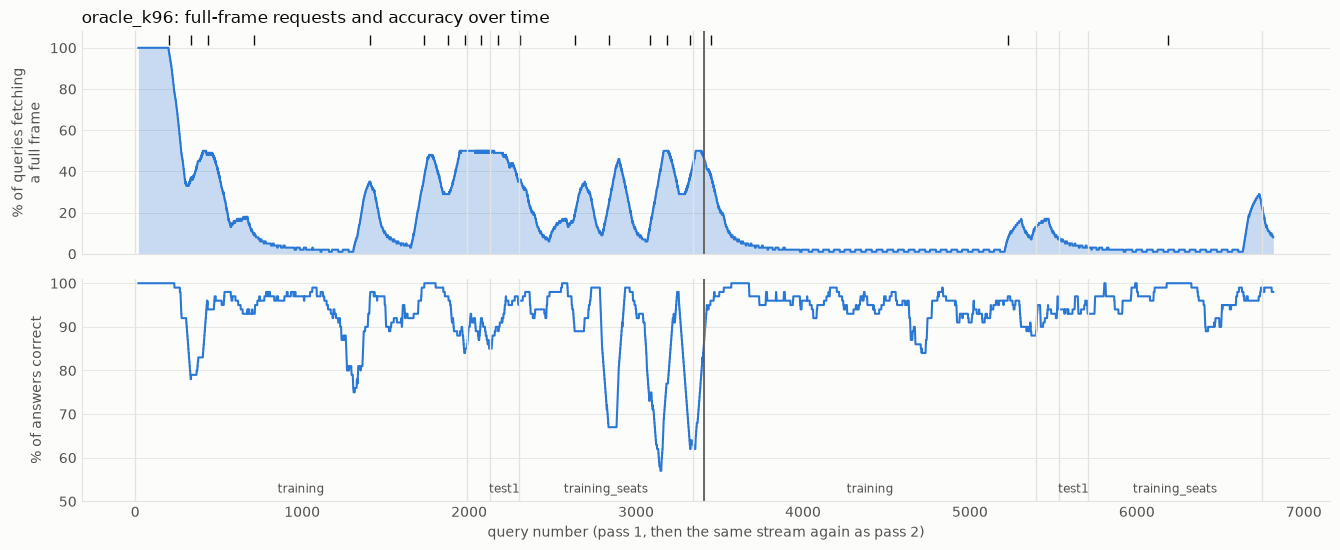

In [4]:
timeline('oracle_k96')

With true labels the accuracy line sits higher throughout and pass 2 stays between 90% and 100% almost everywhere, with 4.5% of queries checked. The remaining dips in pass 1 are in `training_seats`, where the room really has changed and the code has to be relearned. So the mechanism itself is sound; the drop from this picture to the previous one is the detector's label noise.


## 4. What the tag ends up being told

The 96-bit code in use at the end of the detector-labelled run, drawn on an empty-room frame. Each rectangle is a cell the tag sums; darker fill means a larger decoder weight.

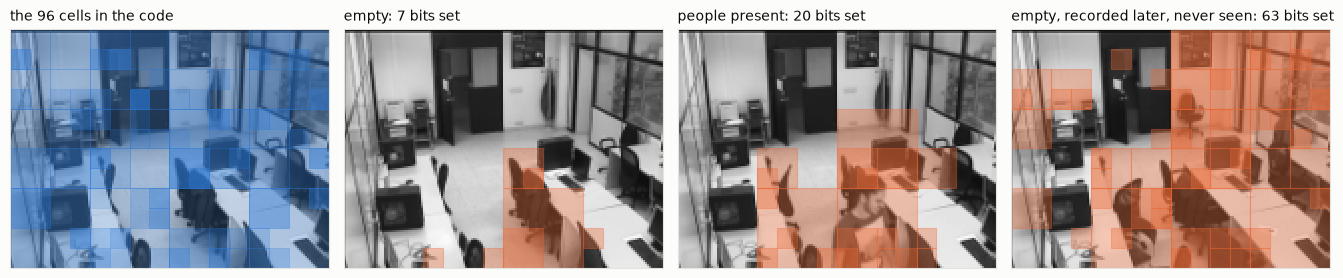

cells by grid: {'16×12 grid': 47, '8×6 grid': 37, '4×3 grid': 12} | instruction size: 288 bytes | reply size: 12 bytes


In [5]:
frames = load_frames(['training_bg', 'test2', 'training_seats'])
c, w = R['adaptive_k96']['code'], np.abs(R['adaptive_k96']['weight'])
by_grid = pd.Series(CELLS[c.cell, 2]).map({40: '4×3 grid', 20: '8×6 grid', 10: '16×12 grid'}).value_counts()

def draw(ax, frame, fired=None):
    ax.imshow(frame, cmap='gray', vmin=0, vmax=255, interpolation='nearest'); ax.set_xticks([]); ax.set_yticks([])
    for j, i in enumerate(c.cell):
        x0, y0, cw, ch = CELLS[i][:4]
        if fired is None:
            ax.add_patch(Rectangle((x0 - .5, y0 - .5), cw, ch, fc=BLUE, alpha=0.12 + 0.5 * w[j] / w.max(), ec=BLUE, lw=0.6))
        elif fired[j]:
            ax.add_patch(Rectangle((x0 - .5, y0 - .5), cw, ch, fc=ORANGE, alpha=0.35, ec=ORANGE, lw=0.8))

EX = [('training_seats', 1179, 'empty'), ('test2', 104, 'people present'), ('training_bg', 30, 'empty, recorded later, never seen')]
fig, axes = plt.subplots(1, 4, figsize=(13.5, 2.9))
draw(axes[0], frames['training_seats']['X'][1179]); axes[0].set_title(f'the {len(c.cell)} cells in the code')
for ax, (seq, i, what) in zip(axes[1:], EX):
    fr = frames[seq]['X'][i]
    fired = code_bits(cell_sums(fr), c)
    draw(ax, fr, fired); ax.set_title(f'{what}: {int(fired.sum())} bits set')
plt.tight_layout(); plt.show()
print('cells by grid:', by_grid.to_dict(), '| instruction size:', c.n_bits // 8, 'bytes | reply size:', c.n_bytes, 'bytes')

**What the code looks like.** The server chose all 12 coarse cells, 37 medium ones and 47 fine ones, spread over most of the frame. For the layout it was last fitted to, an empty room sets about 7 of the 96 bits and a frame with people sets about 20, so most of the payload is zeros and the decoder is counting how many cells are out of their usual range, and where.

The last panel is the same room, empty, in a sequence recorded ten minutes after the stream ends and never shown to the loop: 63 bits are set. The furniture is arranged differently, so most cells are outside the ranges the tag was given. This is the failure a learn-once code runs into, and what continued checking is for.


## Limits of this experiment

* **Thirty minutes, staged.** Each sequence is a different scripted scenario, so "the future looks like the past" barely holds. Pass 2 repeats identical frames, which is optimistic in the other direction. The truth for a real room lies between the two passes and cannot be read off this data.
* **One teacher, one resolution.** The detector sees the 160×120 grayscale frame, where it is far weaker than at full resolution (balanced accuracy 0.86 here).
* **One code family, one set of settings.** Interval bits with a logistic decoder; thresholds, window and schedule were chosen once, not tuned, and there is a single run per configuration. Balanced accuracy here is not comparable with the AUCs in `thumbnail_sweep.ipynb`, which used 3,000 true labels from both layouts.
* **Bytes, not energy.** As before, `semwisp/cost.py` has no measured constants.

## What this suggests next

* **Make checking cheaper.** A full frame is 1,600 times the size of the code, so checks dominate everything. A check could be a 16×12 thumbnail (192 bytes) scored by a room-trained decoder, with the full frame as a rare second step.
* **A better teacher.** Averaging the detector over neighbouring frames, or using a larger model on an upsampled frame, would raise the ceiling shown by the true-label runs.
* **Faster reaction at the floor.** Let the code's own behaviour trigger checks, for example many more bits set than usual, as in the last panel above.
* **Real data.** A multi-day recording of one room is the test this loop is designed for.
